![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Timeline of the Rohingya Exodus: Deforestation in Bangladesh (2016-2018)

In the weeks after 25 August 2017, more than 700,000 Rohingya refugees crossed from Myanmar into
Cox's Bazar, Bangladesh.


## Overview

Kutupalong and Balukhali, modest existing camps, grew within months into
the world's largest refugee settlement. The reserve-forest hillsides around them were cleared for
shelters, firewood and footpaths faster than almost any other land-cover change this notebook
series has looked at. The AOI below covers Camp 4 Extension, Camp 18 and the Balukhali/Moragachhtola
area, matching the screenshot used to define it.

> AOI: 21.213115 N, 92.130199 E to 21.179337 N, 92.166669 E (about 14 km²).

This notebook downloads every usable low-cloud Sentinel-2 L2A date from January 2016 through June
2018, mosaics the two covering MGRS tiles (46QCJ, 46QDJ), tracks a forest mask fixed at the
earliest stable date forward through time, and animates the series. One honest limitation: the
crisis itself began in the June-October monsoon, when this AOI is almost always cloud-covered in
optical imagery, so the clearest "before" and "after" views are a few months apart rather than
bracketing 25 August 2017 exactly. That gap is a real constraint of passive optical monitoring
during the most dynamic part of a fast-moving event.


## Setup

Import the libraries the later cells use, create a local `data` folder, and record whether
Planetary Computer can be reached. `ONLINE` decides whether a missing scene can be downloaded.
`DATA` is where `get_images` writes the clipped GeoTIFFs. A later run finds those files and
skips the download.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup. Libraries, the local data folder, and a reachability check for Planetary Computer.

# 1. Silence the warnings rasterio and xarray raise on ordinary reads. They do not change the values.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# 2. Array, table, and vector libraries, plus the resampling enum used when 20 m bands are
#    matched onto the 10 m grid.
import json
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

# 3. geolattice.rsense reads, mosaics, clips, scales, and masks. search_images queries a STAC
#    catalogue; get_images writes the chosen bands. is_online is only an HTTP check.
import geolattice.rsense as rs
from geolattice.rsense.get_images import get_images, search_images
from geolattice.network import is_online

# 4. Figures in the notebook are drawn at 110 dpi. ONLINE is True only when the Planetary
#    Computer STAC endpoint answers. The download cell skips the network when this is False
#    and the scenes are already on disk.
plt.rcParams.update({"figure.dpi": 110})
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),
      "| Planetary Computer reachable:", ONLINE)

# 5. Scene folders are written under data/, next to the working directory.
DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones")
DATA.mkdir(exist_ok=True)


geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


### Prepare Rohingya AOI and download Sentinel-2 data (2016-2018)

This analysis uses Sentinel-2 L2A imagery collected between 2016 and 2018 over the Rohingya
refugee camp areas (Camp 4 Extension, Camp 18, and Balukhali/Moragachhtola) in Bangladesh.
Fifteen low-cloud dates cover the time before, during, and after the 2017 influx. The area of
interest is the longitude and latitude rectangle in the introduction.

28 July 2017 is left out on purpose. Only one of the two MGRS tiles that cover this rectangle
was available that day, and the clip of that tile is a nine-pixel sliver, too small to use.

`search_images` queries the Planetary Computer `sentinel-2-l2a` collection over the rectangle
from 1 January 2016 through 30 June 2018. When the same date and tile appear more than once,
the greatest item id is kept, which is the latest processing run. `get_images` then writes
only the dates that are not already on disk, clipped to the AOI, for the seven bands listed
in the code.

All data used in this notebook can be found [here](https://www.dropbox.com/scl/fo/c7b6estcd609sp9gdwhuu/AMyl1zO3KuhaiHzB6PiwQkM?rlkey=s458rnzp553y57e02mjx01ri6&dl=0).


In [2]:
# Build the camp rectangle and download any of the 15 dates that are not already under ROH_OUT.

# 1. The rectangle from the screenshot, as a one-row GeoDataFrame in WGS84. box() takes
#    (min x, min y, max x, max y), so longitude comes before latitude. search_images uses this
#    geometry as the spatial filter.
from shapely.geometry import box

ROH_MINLON, ROH_MAXLON = 92.130199, 92.166669   # western and eastern edges, degrees
ROH_MINLAT, ROH_MAXLAT = 21.179337, 21.213115   # southern and northern edges, degrees
ROH_AOI = gpd.GeoDataFrame(geometry=[box(ROH_MINLON, ROH_MINLAT, ROH_MAXLON, ROH_MAXLAT)], crs=4326)
print("Rohingya AOI bounds:", tuple(round(v, 4) for v in ROH_AOI.total_bounds))

# 2. Fifteen low-cloud dates, January 2016 through June 2018. The 17 August and 26 September
#    2017 dates fall in the monsoon and stay in the list so the cloud gap is visible; later
#    cells drop them when the clear fraction is low. 28 July 2017 is absent: only one tile
#    existed that day, and it clipped to a nine-pixel sliver.
ROH_DATES = [
    "2016-01-05", "2016-02-04", "2016-11-20", "2016-12-30",
    "2017-01-09", "2017-02-08", "2017-05-09",
    "2017-08-17", "2017-09-26",                    # monsoon season, heavy residual cloud
    "2017-11-20", "2017-12-15", "2018-01-04", "2018-02-18",
    "2018-03-05", "2018-06-03",
]

# 3. Bands saved for every scene. Blue, green, red, and NIR are the 10 m bands. swir16 is
#    B11 and swir22 is B12, both 20 m. scl is the Scene Classification Layer used as the cloud mask.
ROH_BANDS = ["blue", "green", "red", "nir", "swir16", "swir22", "scl"]
ROH_OUT = DATA / "s2_rohingya_2016_2018"

# 4. Dates already on disk. Each scene is a folder with item.json; the date is the first 10
#    characters of properties.datetime. A folder that cannot be parsed is skipped.
existing_dates = set()
if ROH_OUT.exists():
    for p in ROH_OUT.iterdir():
        if p.is_dir() and (p / "item.json").exists():
            try:
                item = json.loads((p / "item.json").read_text())
                d = item["properties"]["datetime"][:10]
                if d in ROH_DATES:
                    existing_dates.add(d)
            except Exception:
                pass

# 5. If every target date is present, stop. Otherwise, and only when Planetary Computer is
#    reachable, search the whole window and download the missing dates. The inner loop keeps,
#    for each (date, MGRS tile), the item with the greater id. get_images clips those items
#    to the AOI and writes one folder per scene. Offline, the cell reports what is already local.
missing_dates = sorted(set(ROH_DATES) - existing_dates)
if len(existing_dates) == len(ROH_DATES):
    print(f"All {len(ROH_DATES)} target scenes already present in {ROH_OUT}")
elif ONLINE and missing_dates:
    print(f"Found {len(existing_dates)} of {len(ROH_DATES)} required scenes locally. Downloading missing scenes for dates: {missing_dates}")
    found = search_images(aoi=ROH_AOI, dates=("2016-01-01", "2018-06-30"), source="planetary",
                          collection="sentinel-2-l2a", limit=250, quiet=True)
    latest = {}
    for item in found.items:
        d = item.datetime.date().isoformat()
        if d not in missing_dates:
            continue
        key = (d, item.properties.get("s2:mgrs_tile"))
        if key not in latest or item.id > latest[key]:
            latest[key] = item.id
    ids = sorted(latest.values())
    if ids:
        saved = get_images(ROH_OUT, search=found, ids=ids, bands=ROH_BANDS, mode="clip", quiet=True)
        print(f"{len(saved.scenes)} new scenes downloaded for {len(ids)} target dates "
              f"({len(saved.failures)} failures), tiles {sorted({k[1] for k in latest})}")
    else:
        print("No images to download for missing dates:", missing_dates)
else:
    if len(existing_dates) == 0:
        print("No scenes found locally under", ROH_OUT)
    else:
        print(f"{len(existing_dates)} of {len(ROH_DATES)} target scenes already present under {ROH_OUT}; skipping download (offline or no access)")


Rohingya AOI bounds: (np.float64(92.1302), np.float64(21.1793), np.float64(92.1667), np.float64(21.2131))
All 15 target scenes already present in data/s2_rohingya_2016_2018


### Mosaic, resample, and clip Sentinel-2 tiles for Rohingya AOI

Each date is covered by two MGRS tiles, 46QCJ and 46QDJ. This cell reads every scene folder,
groups the folders by acquisition date, puts the two tiles on one grid, and clips that mosaic
to the camp rectangle.

Blue, green, red, and NIR are already 10 m. SWIR1 (B11, `swir16`) and SWIR2 (B12, `swir22`)
are 20 m, so each is resampled with bilinear interpolation onto the 10 m red grid before the
mosaic. The Scene Classification Layer is resampled with nearest neighbour so the class codes
stay whole numbers instead of being averaged.

`rs.mosaic` merges the tiles onto the grid of the first raster. Where the tiles overlap, the
default method `"first"` keeps the earlier folder in sorted path order; it does not average
them. `rs.clip` then cuts the mosaic to the AOI after that polygon has been projected into the
scene CRS.

The result is one `xarray` Dataset, `s2_roh`, with a `time` coordinate. The CRS written onto
it is the CRS of the first red band.


In [3]:
# Mosaic the two tiles of each date, put every band on the 10 m grid, and clip to the AOI.

# 1. Band groups. The four 10 m bands are read at their native spacing. The two SWIR bands
#    are 20 m and are resampled below. ROH_ALL is the order of the reflectance variables.
ROH_10M = ["blue", "green", "red", "nir"]
ROH_20M = ["swir16", "swir22"]
ROH_ALL = ROH_10M + ROH_20M

# 2. Group scene folders by calendar date. item.json is the STAC item saved beside the bands;
#    the date is the first 10 characters of properties.datetime. One date usually has two folders,
#    one per MGRS tile.
roh_by_date = defaultdict(list)
for scene_dir in sorted(p for p in ROH_OUT.iterdir() if p.is_dir()):
    item = json.loads((scene_dir / "item.json").read_text())
    roh_by_date[item["properties"]["datetime"][:10]].append(scene_dir)

# 3. Walk the dates in order. Red defines the 10 m grid and the CRS. The AOI is projected into
#    that CRS once, on the first tile, and reused for every later clip.
roh_aoi_utm = None
roh_cube_vars = {b: [] for b in ROH_ALL}
roh_scl_list, roh_times = [], []
for d in sorted(roh_by_date):
    tile_arrays = {b: [] for b in ROH_ALL}
    tile_scl = []
    for td in roh_by_date[d]:
        red10 = rs.read(td / "red.tif", masked=False).squeeze("band", drop=True)
        if roh_aoi_utm is None:
            roh_aoi_utm = ROH_AOI.to_crs(red10.rio.crs)
        # 4. 10 m bands are appended as read. SWIR is bilinearly matched to red, which
        #    interpolates the 20 m values onto the 10 m pixels. SCL uses nearest neighbour
        #    so a pixel keeps one class code.
        for b in ROH_10M:
            tile_arrays[b].append(rs.read(td / f"{b}.tif", masked=False).squeeze("band", drop=True))
        for b in ROH_20M:
            arr = rs.read(td / f"{b}.tif", masked=False).squeeze("band", drop=True)
            tile_arrays[b].append(arr.rio.reproject_match(red10, resampling=Resampling.bilinear))
        scl = rs.read(td / "scl.tif", masked=False).squeeze("band", drop=True)
        tile_scl.append(scl.rio.reproject_match(red10, resampling=Resampling.nearest))

    # 5. Mosaic the tiles of this date, then clip to the camp polygon. One 2D array per band
    #    is stored for this date, plus one SCL array, plus the timestamp.
    clipped = {b: rs.clip(rs.mosaic(tile_arrays[b]), roh_aoi_utm) for b in ROH_ALL}
    for b in ROH_ALL:
        roh_cube_vars[b].append(clipped[b])
    roh_scl_list.append(rs.clip(rs.mosaic(tile_scl), roh_aoi_utm))
    roh_times.append(pd.Timestamp(d))

# 6. Stack the dates along a time coordinate. join="outer" keeps the union of the coordinates
#    if two dates do not line up exactly. The CRS is copied from the first red mosaic, because
#    concat does not carry the rioxarray CRS through on its own.
roh_time_idx = pd.DatetimeIndex(roh_times).rename("time")
s2_roh = xr.Dataset({b: xr.concat(roh_cube_vars[b], dim=roh_time_idx, join="outer") for b in ROH_ALL})
s2_roh["scl"] = xr.concat(roh_scl_list, dim=roh_time_idx, join="outer")
s2_roh = s2_roh.rio.write_crs(roh_cube_vars["red"][0].rio.crs)
print(dict(s2_roh.sizes), s2_roh.rio.crs)


{'x': 380, 'y': 376, 'time': 16} EPSG:32646


### Scale and mask clouds

Level-2A files store digital numbers, not reflectance. `rs.optical.scale` converts Sentinel-2
L2A with `(DN + offset) / 10000`. The offset is 0 before 25 January 2022 and -1000 after that,
taken from the acquisition date. Every date in this cube is from 2016 to 2018, so the offset
is 0 and reflectance is DN / 10000. The SCL layer is not passed in, so it is not scaled.

`rs.optical.s2_scl_mask` is True where the pixel is usable. By default it rejects no-data (0),
saturated or defective (1), cloud shadow (3), medium and high cloud probability (8 and 9), and
thin cirrus (10). Vegetation, bare ground, water, unclassified, dark, and snow stay in the mask
unless extra flags are set. `where` sets reflectance to NaN wherever the mask is False.

NDVI is `(NIR - red) / (NIR + red)` from `.rs.index("NDVI")`, computed on the masked reflectance,
so cloudy pixels do not enter the index.

Pixel area in hectares is the absolute product of the x and y spacing, divided by 10,000
(square metres per hectare). The clear fraction of each date is the spatial mean of the mask.
Later cells use that fraction to drop the monsoon dates.


In [4]:
# Scale the cube to reflectance, mask clouds with the SCL, and compute NDVI.

# 1. Reflectance for the six optical bands only. SCL stays in s2_roh as class codes.
refl_roh = rs.optical.scale(s2_roh[ROH_ALL], sensor="sentinel2")

# 2. Boolean mask, True on usable pixels. clean_roh is reflectance with clouds and shadows
#    set to NaN. NDVI is then (nir - red) / (nir + red) on that masked cube.
valid_roh = rs.optical.s2_scl_mask(s2_roh["scl"])
clean_roh = refl_roh.where(valid_roh)
ndvi_roh = clean_roh.rs.index("NDVI")

# 3. Ground area of one pixel, in hectares, from the grid spacing. The clear fraction is the
#    fraction of AOI pixels the SCL kept on each date. Printed to three decimals so the two
#    monsoon dates are easy to see.
px_ha = abs(float(s2_roh.x[1] - s2_roh.x[0]) * float(s2_roh.y[1] - s2_roh.y[0])) / 10000
vf_roh = valid_roh.mean(("y", "x")).to_series()
print(f"Pixel area: {px_ha * 10000:.0f} m^2 | clear fraction per date (SCL-valid):")
print(vf_roh.round(3))


Pixel area: 100 m^2 | clear fraction per date (SCL-valid):
time
2016-01-05    0.991
2016-02-04    0.990
2016-11-20    0.990
2016-12-30    0.990
2017-01-09    0.990
2017-02-08    0.991
2017-05-09    0.764
2017-07-28    0.000
2017-08-17    0.065
2017-09-26    0.879
2017-11-20    0.959
2017-12-15    0.929
2018-01-04    0.912
2018-02-18    0.990
2018-03-05    0.763
2018-06-03    0.179
Name: valid, dtype: float64


### Forest Change Detection: Before and After the 2017 Crisis

A clear winter date before the influx, 5 January 2016, is compared with a clear winter date
after it. Pairing the same season keeps ordinary leaf-on greening from looking like forest
change. Forest on a date is NDVI greater than 0.5 on a pixel the SCL marked as clear.

The change code is `2 * forest_before + forest_after`, with each forest map stored as 0 or 1:

| Code | Meaning |
|---|---|
| 0 | Non-forest on both dates |
| 1 | Gained (not forest before, forest after) |
| 2 | Lost (forest before, not forest after) |
| 3 | Forest on both dates |

The requested "after" day is 8 January 2018, which is not in `ROH_DATES`. The cell then takes
the nearest date in the cube. That date is 4 January 2018. The panel titles still print the
requested timestamps, including 8 January 2018, rather than the date that was substituted.

Loss in hectares is the count of code-2 pixels times the pixel area. The percentage uses the
5 January 2016 forest area as the baseline.


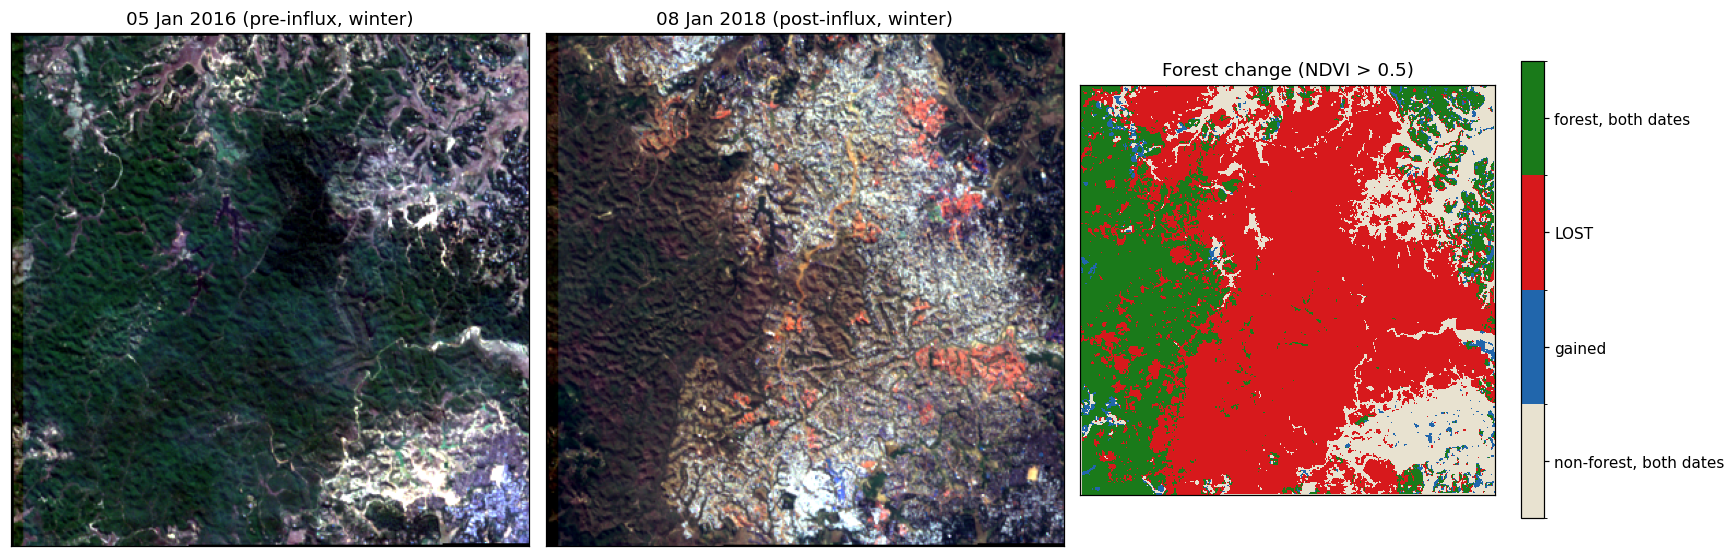

Of the 1142 ha classed as forest on 05 Jan 2016, 795 ha (69.6%) was cleared by 08 Jan 2018.


In [5]:
# True-colour before and after the influx, plus a forest-change map between those two dates.

# 1. Winter endpoints. 5 January 2016 is in the cube. 8 January 2018 is not: the nearest
#    downloaded date is 4 January 2018, and get_loc raises KeyError for the missing day.
before_t = pd.Timestamp("2016-01-05")  # winter, pre-influx, cloud-free
after_t = pd.Timestamp("2018-01-08")   # requested post-influx day; substituted below if absent

before_i = int(roh_time_idx.get_loc(before_t))
try:
    after_i = int(roh_time_idx.get_loc(after_t))
except KeyError:
    # Index of the timestamp closest to the requested day. The title below still uses after_t.
    after_i = int((np.abs(roh_time_idx - after_t)).argmin())
    print(f"Warning: Date {after_t.strftime('%Y-%m-%d')} not found. Using closest date: {roh_time_idx[after_i].strftime('%Y-%m-%d')}")

# 2. Forest is NDVI above 0.5 and clear on that date. The integer code packs the two maps:
#    lost pixels are 2, gained pixels are 1, stable forest is 3, stable non-forest is 0.
forest_before = (ndvi_roh.isel(time=before_i) > 0.5) & valid_roh.isel(time=before_i)
forest_after = (ndvi_roh.isel(time=after_i) > 0.5) & valid_roh.isel(time=after_i)
change = forest_before.astype(int) * 2 + forest_after.astype(int)

# 3. True colour uses the unscaled digital numbers with a 1st to 99th percentile stretch, so
#    the two dates can be compared visually. The third panel is the four-class change map.
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
rs.viz.plot_rgb(s2_roh.isel(time=before_i), ["red", "green", "blue"], ax=axes[0],
                title=f"{before_t:%d %b %Y} (pre-influx, winter)", p=(1, 99))
rs.viz.plot_rgb(s2_roh.isel(time=after_i), ["red", "green", "blue"], ax=axes[1],
                title=f"{after_t:%d %b %Y} (post-influx, winter)", p=(1, 99))
rs.viz.plot_raster(change, ax=axes[2], title="Forest change (NDVI > 0.5)",
                   categorical={0: ("non-forest, both dates", "#e8e2d0"),
                                1: ("gained", "#2166ac"),
                                2: ("LOST", "#d7191c"),
                                3: ("forest, both dates", "#1a7a1a")})
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

# 4. Hectares lost are code-2 pixels times the pixel area. The share is that area divided by
#    the forest area on the "before" date.
lost_px = int((change == 2).sum())
base_px = int(forest_before.sum())
print(f"Of the {base_px * px_ha:.0f} ha classed as forest on {before_t:%d %b %Y}, "
      f"{lost_px * px_ha:.0f} ha ({lost_px / base_px:.1%}) was cleared by {after_t:%d %b %Y}.")


A clear band of cleared land cuts across the centre of the AOI between May and November 2017,
exactly where the camp expanded. Counting "any pixel with NDVI > 0.5" independently on each date
mixes this real clearing with ordinary seasonal greening elsewhere in the scene (crops, regrowth),
so the deforestation rate below instead fixes the forest mask once, at the earliest stable date,
and tracks how much of that same footprint survives on each later date.


### Deforestation trend: fixing the baseline forest and tracking what remains

The two-date map above can call a seasonally green field "forest" on one date and not on
another. This cell avoids that. The forest mask is taken only from the first date in the cube,
5 January 2016, which is a clear winter scene: NDVI greater than 0.5 and SCL-valid. Every later
date is then asked a narrower question: of those same pixels that are cloud-free on this date,
what fraction still has NDVI above 0.5?

Pixels of the baseline forest that are cloudy on a given date are left out of both the numerator
and the denominator, so a cloud does not look like clearing. The two monsoon dates, where the
clear fraction is 0.3 or below, are dropped from the table and the plot. The vertical line is
25 August 2017, the start of the influx, not an acquisition date.


Baseline forest, 05 Jan 2016: 1142 ha

            clear_frac  pct_of_baseline
date                                   
2016-01-05       0.991            100.0
2016-02-04       0.990             83.6
2016-11-20       0.990             98.8
2016-12-30       0.990             94.4
2017-01-09       0.990             94.4
2017-02-08       0.991             84.5
2017-05-09       0.764             60.2
2017-09-26       0.879             75.8
2017-11-20       0.959             46.5
2017-12-15       0.929             38.4
2018-01-04       0.912             33.3
2018-02-18       0.990              6.5
2018-03-05       0.763              1.9


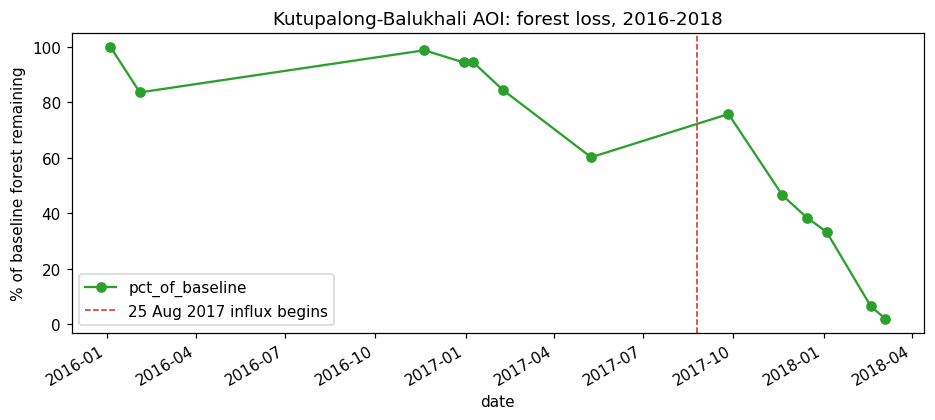

In [6]:
# Fix the forest mask on the first date and track how much of that footprint is still forest.

# 1. Baseline forest: the earliest date (index 0, 5 January 2016), NDVI above 0.5, and clear.
#    baseline_ha is that mask times the pixel area.
baseline_i = 0                                                     # 2016-01-05
baseline_forest = (ndvi_roh.isel(time=baseline_i) > 0.5) & valid_roh.isel(time=baseline_i)
baseline_ha = float(baseline_forest.sum()) * px_ha

# 2. One row per date. observed is the baseline-forest pixels that are clear on this date, so
#    clouds inside the old forest are not counted as loss. frac_remaining is the share of those
#    observed pixels that still exceed NDVI 0.5. An empty observation (fully cloudy baseline)
#    is stored as NaN rather than a division by zero.
rows = []
for i, t in enumerate(roh_time_idx):
    observed = valid_roh.isel(time=i) & baseline_forest        # baseline-forest pixels seen this date
    observed_ha = float(observed.sum()) * px_ha
    still_forest_ha = float(((ndvi_roh.isel(time=i) > 0.5) & observed).sum()) * px_ha
    rows.append((t, float(vf_roh.iloc[i]), observed_ha,
                 still_forest_ha / observed_ha if observed_ha > 0 else np.nan))
trend = pd.DataFrame(rows, columns=["date", "clear_frac", "baseline_observed_ha", "frac_remaining"]).set_index("date")
trend["pct_of_baseline"] = (trend.frac_remaining * 100).round(1)

# 3. Drop dates that are 30 percent clear or less. Those are the two monsoon scenes. Print the
#    clear fraction and the percent of the baseline still forest, then plot that percent.
#    The dashed line marks 25 August 2017.
good = trend[trend.clear_frac > 0.3]                            # drop the two heavily clouded dates
print(f"Baseline forest, {roh_time_idx[baseline_i]:%d %b %Y}: {baseline_ha:.0f} ha\n")
print(good[["clear_frac", "pct_of_baseline"]].round(3))

ax = (good.pct_of_baseline).plot(style="o-", ms=6, figsize=(10, 4), color="C2")
ax.axvline(pd.Timestamp("2017-08-25"), color="C3", ls="--", lw=1, label="25 Aug 2017 influx begins")
ax.set(ylabel="% of baseline forest remaining", title="Kutupalong-Balukhali AOI: forest loss, 2016-2018")
ax.legend(); plt.show()


### Forest lost

The trend table is turned into a rate. The last relatively clear date before the influx in
this stack is 9 May 2017, and the first relatively clear date after the monsoon is
20 November 2017. Those two rows of `good` give the forest area still standing, as
`frac_remaining` times the January 2016 baseline area.

The rate is the difference in hectares divided by the number of days between those dates,
also expressed per month using 30.4 days. The last row of `good` is the end of the series
(3 June 2018) and is reported the same way: hectares of the 2016 footprint still classed as
forest, and hectares gone.


In [7]:
# Report forest loss from 9 May 2017 to 20 November 2017, and through the last clear date.

# 1. Areas still forest on the two dates, in hectares of the January 2016 footprint.
#    days is the gap between them, not the gap between the acquisitions' neighbours.
pre = good.loc["2017-05-09"]
post = good.loc["2017-11-20"]
days = (pd.Timestamp("2017-11-20") - pd.Timestamp("2017-05-09")).days
pre_ha, post_ha = pre.frac_remaining * baseline_ha, post.frac_remaining * baseline_ha
rate_ha_month = (pre_ha - post_ha) / days * 30.4

# 2. The last clear date in the filtered table, and the same conversion from fraction to hectares.
final = good.iloc[-1]
final_ha = final.frac_remaining * baseline_ha

# 3. Print the two areas, the daily and monthly rates across that gap, and the area gone
#    by the end of the series relative to the January 2016 baseline.
print(f"Still forest, {pre.name:%d %b %Y}: {pre_ha:.0f} ha ({pre.pct_of_baseline:.0f}% of baseline)")
print(f"Still forest, {post.name:%d %b %Y}: {post_ha:.0f} ha ({post.pct_of_baseline:.0f}% of baseline)")
print(f"Deforestation rate across those {days} days: {(pre_ha - post_ha) / days:.2f} ha/day "
      f"= {rate_ha_month:.0f} ha/month")
print(f"\nBy {final.name:%d %b %Y}: {final_ha:.0f} ha remaining ({final.pct_of_baseline:.0f}% of "
      f"baseline). {baseline_ha - final_ha:.0f} ha ({100 - final.pct_of_baseline:.0f}%) of the "
      f"2016 forest footprint in this AOI was gone within about a year and a half.")


Still forest, 09 May 2017: 687 ha (60% of baseline)
Still forest, 20 Nov 2017: 531 ha (46% of baseline)
Deforestation rate across those 195 days: 0.80 ha/day = 24 ha/month

By 05 Mar 2018: 22 ha remaining (2% of baseline). 1119 ha (98%) of the 2016 forest footprint in this AOI was gone within about a year and a half.


### Animate the clear dates

The same cube, drawn as a false-colour sequence: NIR on red, red on green, and green on blue.
Vegetation is bright in the NIR, so standing forest reads red. Cleared ground and bare soil
reflect less in the NIR and read cyan to white.

Only dates with a clear fraction above 0.3 are included, the same cutoff as the trend plot,
so the two monsoon scenes do not flash a mostly empty frame. Each frame is stretched to an
8-bit RGB image with `make_rgb`, NaNs are filled with 0, and the frames are written to
`outputs/rohingya_deforestation_cloudfree.gif` at two frames per second.


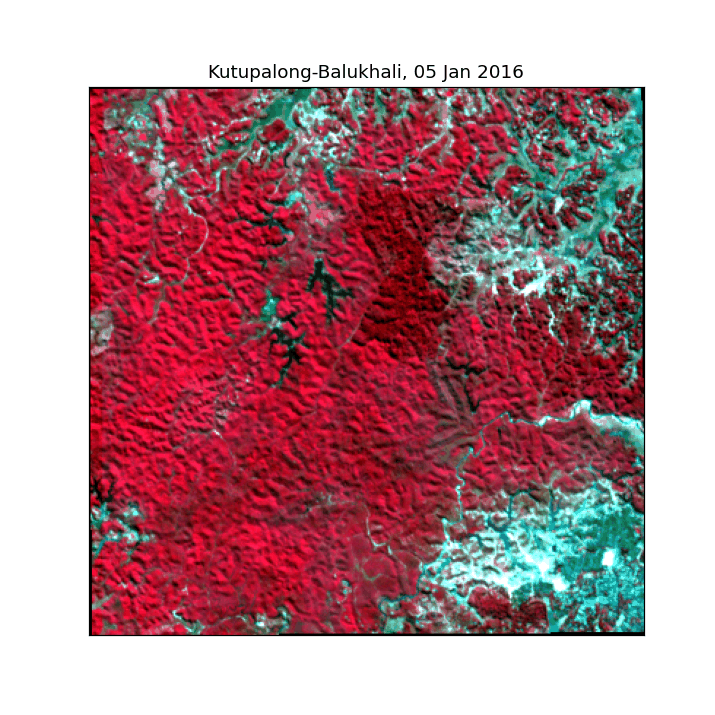

In [8]:
# Animate the dates that are more than 30 percent clear. False colour: NIR, red, green.

# 1. Pillow writes the GIF. make_rgb stretches the three bands to an 8-bit RGB image using
#    the same percentile stretch as plot_rgb. The GIF is saved under outputs/.
import matplotlib.animation as animation
from IPython.display import Image as IPImage
from geolattice.rsense.viz.stretch import rgb as make_rgb

ROH_OUT_DIR = Path("outputs")
ROH_OUT_DIR.mkdir(exist_ok=True)

# 2. Keep the time indexes whose clear fraction is above 0.3, and build one RGB frame for
#    each. nan_to_num turns masked (cloudy) pixels into 0, which displays as black.
CLOUD_FREE_THRESHOLD = 0.3
cloud_free_idxs = [i for i, cf in enumerate(vf_roh) if cf > CLOUD_FREE_THRESHOLD]

roh_frames_cf = [
    np.nan_to_num(make_rgb(s2_roh.isel(time=k), ["nir", "red", "green"]).values)
    for k in cloud_free_idxs
]
roh_time_idx_cf = [roh_time_idx[k] for k in cloud_free_idxs]
vf_roh_cf = vf_roh.iloc[cloud_free_idxs]

# 3. One axes, updated in place. The title is the acquisition date of that frame.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
im = ax.imshow(roh_frames_cf[0], origin="upper")
ax.set_xticks([]); ax.set_yticks([])
ttl = ax.set_title("")

def _update_roh_cf(k):
    im.set_data(roh_frames_cf[k])
    t = roh_time_idx_cf[k]
    ttl.set_text(f"Kutupalong-Balukhali, {t:%d %b %Y}")
    return im, ttl

# 4. 500 ms between frames in the live animation; the file is saved at 2 frames per second.
#    The figure is closed so it is not also drawn as a static plot, and the GIF is shown.
anim = animation.FuncAnimation(fig, _update_roh_cf, frames=len(roh_frames_cf), interval=500)
gif_path = ROH_OUT_DIR / "rohingya_deforestation_cloudfree.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=2))
plt.close(fig)
IPImage(filename=str(gif_path))


## Summary and Conclusions

In this notebook, we investigated deforestation in the Kutupalong-Balukhali refugee camps area, driven by the Rohingya exodus in Bangladesh. Using Sentinel-2 multispectral imagery and advanced remote sensing techniques, we analyzed vegetation changes over several years.

We preprocessed satellite data, performed cloud and shadow masking using Sentinel-2's Scene Classification Layer (SCL), and focused on cloud-free pixels to improve accuracy. By computing common vegetation indices such as NDVI and EVI, we quantified vegetation cover and its change over time. Visualizations highlighted a significant reduction in healthy vegetation in and around the refugee camp area, especially following the influx of refugees in 2017.

Our time series analyses, including both summary plots and animations, revealed that deforestation was rapid and extensive after the camp's expansion. The techniques demonstrated in this notebook—including data loading, quality masking, index computation, and visualization, provide a robust workflow for monitoring land cover change due to humanitarian crises or other rapid-development events.

In conclusion, satellite-based remote sensing is a powerful tool for monitoring environmental impacts of large-scale human migrations. It enables evidence-based decision-making to address both humanitarian needs and environmental conservation.
